<a href="https://colab.research.google.com/github/mohamadnurtaufiq/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_6_Pembelajaran_Mesin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Buka di Google Colab"/></a>

# Bab 6 — Pembelajaran Mesin Statistik

## Gambaran kegiatan

Pada bab ini kita mencoba beberapa algoritma pembelajaran mesin untuk memperkirakan nilai numerik. Berbeda dari klasifikasi pada bab sebelumnya, target kali ini berupa angka, bukan nama kelompok.

Kita menggunakan dataset diabetes bawaan scikit-learn. Data ini berisi beberapa ukuran kesehatan dan target numerik yang menggambarkan perkembangan penyakit setelah satu tahun. Dataset ini hanya dipakai sebagai bahan latihan statistik, bukan untuk membuat keputusan medis.

Yang akan dicoba:
- K-Nearest Neighbors untuk regresi
- Pohon Keputusan untuk regresi
- Random Forest
- Gradient Boosting
- Validasi silang dan pengukuran kesalahan prediksi

## 1. Menyiapkan alat analisis

Jalankan sel berikut untuk memanggil pustaka yang dibutuhkan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 31

## 2. Memahami dataset

Kita tampilkan beberapa baris awal, ukuran dataset, dan ringkasan statistik. Langkah ini membantu memastikan data sudah berhasil dimuat dan memberi gambaran rentang setiap fitur.

In [2]:
data = load_diabetes(as_frame=True)
X = data.data
y = data.target

print("Ukuran fitur:", X.shape)
print("Jumlah target:", y.shape[0])
print("Nama fitur:", list(X.columns))

display(X.head())
display(X.describe().round(3))

Ukuran fitur: (442, 10)
Jumlah target: 442
Nama fitur: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136


## 3. Memeriksa hubungan fitur dengan target

Grafik berikut memperlihatkan hubungan salah satu fitur dengan nilai target. Pola yang tampak dapat membantu membangun intuisi, tetapi satu grafik saja belum cukup untuk menyimpulkan hubungan sebab-akibat.

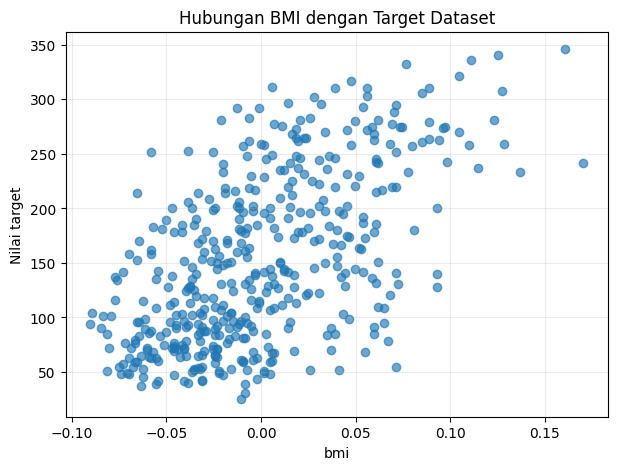

,Korelasi dengan target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


In [3]:
fitur_pilihan = "bmi"

plt.figure(figsize=(7, 5))
plt.scatter(X[fitur_pilihan], y, alpha=0.65)
plt.xlabel(fitur_pilihan)
plt.ylabel("Nilai target")
plt.title("Hubungan BMI dengan Target Dataset")
plt.grid(alpha=0.25)
plt.show()

korelasi = pd.concat([X, y.rename("target")], axis=1).corr(numeric_only=True)["target"]
display(korelasi.drop("target").sort_values(key=abs, ascending=False).to_frame("Korelasi dengan target"))

## 4. Membagi data

Sebagian data digunakan untuk melatih model dan sebagian lainnya disimpan untuk pengujian. Dengan cara ini, penilaian model dilakukan pada data yang tidak dipakai saat pelatihan.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED
)

print(f"Data latihan: {X_train.shape[0]} baris")
print(f"Data pengujian: {X_test.shape[0]} baris")

Data latihan: 331 baris
Data pengujian: 111 baris


## 5. Menentukan ukuran kesalahan

Untuk membandingkan model regresi, kita memakai tiga ukuran:

- **MAE**: rata-rata nilai absolut selisih prediksi dan nilai sebenarnya. Semakin kecil semakin baik.
- **RMSE**: akar dari rata-rata kuadrat kesalahan. Kesalahan besar mendapat penalti lebih tinggi.
- **R²**: ukuran seberapa baik model menjelaskan variasi target. Nilai yang lebih tinggi biasanya lebih baik; nilainya dapat negatif jika model sangat buruk.

In [5]:
def nilai_model(nama, model, X_uji, y_uji):
    prediksi = model.predict(X_uji)
    return {
        "Model": nama,
        "MAE": mean_absolute_error(y_uji, prediksi),
        "RMSE": mean_squared_error(y_uji, prediksi) ** 0.5,
        "R2": r2_score(y_uji, prediksi)
    }

## 6. Model pertama: K-Nearest Neighbors untuk regresi

KNN memperkirakan nilai sampel baru dari nilai beberapa sampel yang paling dekat. Karena perhitungan jarak sensitif terhadap skala fitur, normalisasi dimasukkan ke dalam rangkaian model.

In [6]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=9, weights="distance")
)
knn.fit(X_train, y_train)

hasil_knn = knn.predict(X_test)
print("Contoh lima prediksi pertama:")
display(pd.DataFrame({
    "Nilai sebenarnya": y_test.iloc[:5].to_numpy(),
    "Prediksi KNN": hasil_knn[:5]
}).round(2))

Contoh lima prediksi pertama:


,Nilai sebenarnya,Prediksi KNN
0,201.0,136.68
1,64.0,106.19
2,265.0,166.40
3,131.0,177.02
4,178.0,159.50


## 7. Model kedua: Pohon Keputusan

Pohon regresi membagi data menjadi beberapa bagian berdasarkan aturan fitur. Model ini mudah divisualisasikan, tetapi pohon yang terlalu dalam dapat menghafal data latihan dan kurang baik pada data baru.

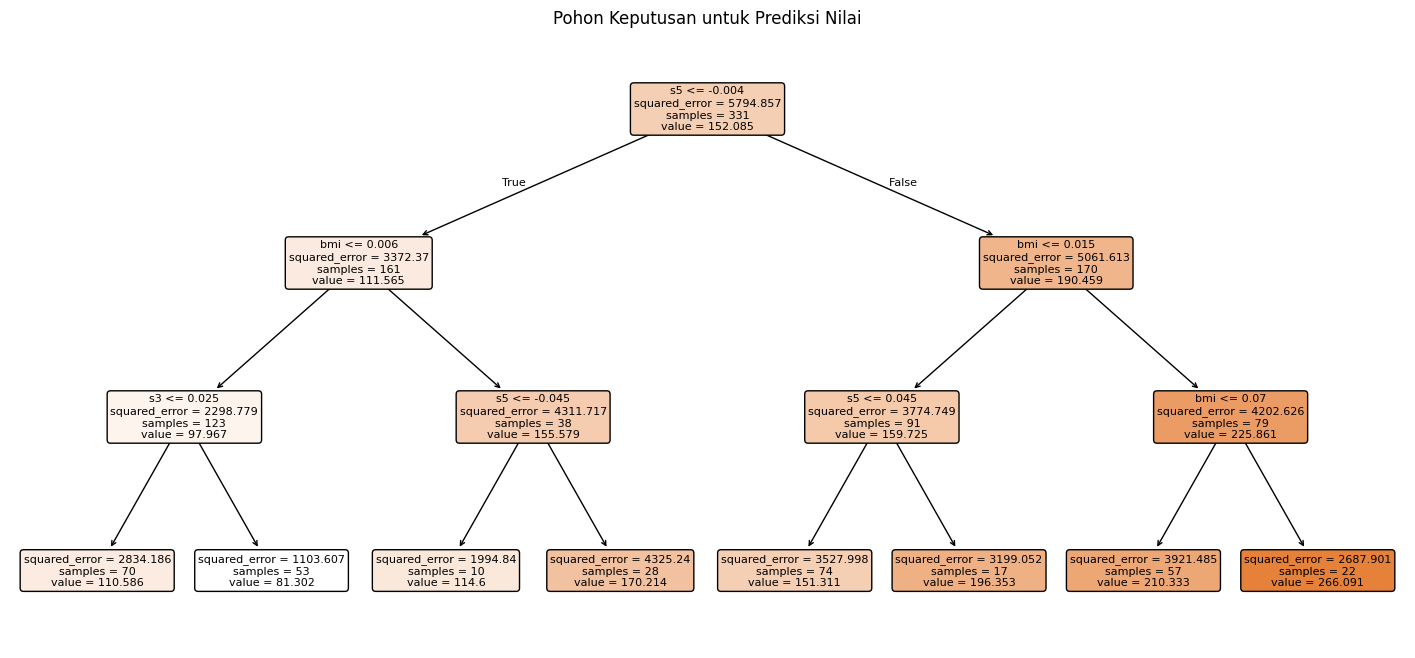

In [7]:
pohon = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=8,
    random_state=SEED
)
pohon.fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(
    pohon,
    feature_names=list(X.columns),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Pohon Keputusan untuk Prediksi Nilai")
plt.show()

## 8. Model ketiga: Random Forest

Random Forest menggabungkan banyak pohon yang dilatih dengan variasi sampel dan fitur. Penggabungan hasil banyak pohon biasanya membuat prediksi lebih stabil dibandingkan satu pohon saja.

In [8]:
hutan = RandomForestRegressor(
    n_estimators=250,
    min_samples_leaf=3,
    random_state=SEED
)
hutan.fit(X_train, y_train)

print("Lima prediksi pertama dari Random Forest:")
display(pd.DataFrame({
    "Nilai sebenarnya": y_test.iloc[:5].to_numpy(),
    "Prediksi Random Forest": hutan.predict(X_test)[:5]
}).round(2))

Lima prediksi pertama dari Random Forest:


,Nilai sebenarnya,Prediksi Random Forest
0,201.0,125.48
1,64.0,92.36
2,265.0,224.70
3,131.0,175.65
4,178.0,159.32


## 9. Model keempat: Gradient Boosting

Gradient Boosting membangun model secara bertahap. Setiap tahap berikutnya berusaha memperbaiki kesalahan yang masih tersisa dari model sebelumnya. Hasilnya dapat kuat, tetapi parameter seperti jumlah pohon dan kedalaman perlu dipilih dengan hati-hati.

In [9]:
boosting = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.04,
    max_depth=2,
    random_state=SEED
)
boosting.fit(X_train, y_train)

print("Lima prediksi pertama dari Gradient Boosting:")
display(pd.DataFrame({
    "Nilai sebenarnya": y_test.iloc[:5].to_numpy(),
    "Prediksi Gradient Boosting": boosting.predict(X_test)[:5]
}).round(2))

Lima prediksi pertama dari Gradient Boosting:


,Nilai sebenarnya,Prediksi Gradient Boosting
0,201.0,123.37
1,64.0,104.11
2,265.0,204.73
3,131.0,164.68
4,178.0,161.01


## 10. Membandingkan seluruh model

Semua model diuji pada bagian data pengujian yang sama. Perhatikan MAE dan RMSE yang lebih rendah serta R² yang lebih tinggi. Hasil terbaik pada satu pembagian data belum tentu menjadi yang terbaik pada pembagian lain.

In [10]:
model_list = [
    ("KNN", knn),
    ("Pohon Keputusan", pohon),
    ("Random Forest", hutan),
    ("Gradient Boosting", boosting)
]

perbandingan = pd.DataFrame([
    nilai_model(nama, model, X_test, y_test)
    for nama, model in model_list
]).sort_values("RMSE")

display(perbandingan.round(3))

,Model,MAE,RMSE,R2
2,Random Forest,41.124,52.224,0.569
3,Gradient Boosting,42.327,54.368,0.533
0,KNN,43.096,55.234,0.518
1,Pohon Keputusan,42.513,55.412,0.515


## 11. Validasi silang

Satu kali pembagian data dapat memberikan hasil yang kebetulan terlalu baik atau terlalu buruk. Validasi silang membagi data latihan menjadi beberapa lipatan. Model dilatih dan dinilai berulang kali sehingga kita memperoleh gambaran kinerja yang lebih stabil.

Di sini kita memakai nilai negatif RMSE dari scikit-learn lalu mengubah tandanya agar hasilnya mudah dibaca sebagai RMSE positif.

In [11]:
lipatan = KFold(n_splits=5, shuffle=True, random_state=SEED)

hasil_cv = []
for nama, model in model_list:
    skor = cross_val_score(
        model,
        X_train,
        y_train,
        cv=lipatan,
        scoring="neg_root_mean_squared_error"
    )
    hasil_cv.append({
        "Model": nama,
        "Rata-rata RMSE validasi": -skor.mean(),
        "Simpangan baku RMSE": skor.std()
    })

display(pd.DataFrame(hasil_cv).sort_values("Rata-rata RMSE validasi").round(3))

,Model,Rata-rata RMSE validasi,Simpangan baku RMSE
3,Gradient Boosting,57.772,1.800
2,Random Forest,59.530,3.517
0,KNN,59.616,3.120
1,Pohon Keputusan,65.174,4.777


## 12. Melihat fitur penting pada Random Forest

Random Forest menyediakan perkiraan kontribusi relatif fitur untuk membantu pembagian pada pohon. Nilai ini berguna untuk eksplorasi, tetapi **tidak membuktikan bahwa fitur menyebabkan perubahan target** dan dapat dipengaruhi oleh karakteristik data.

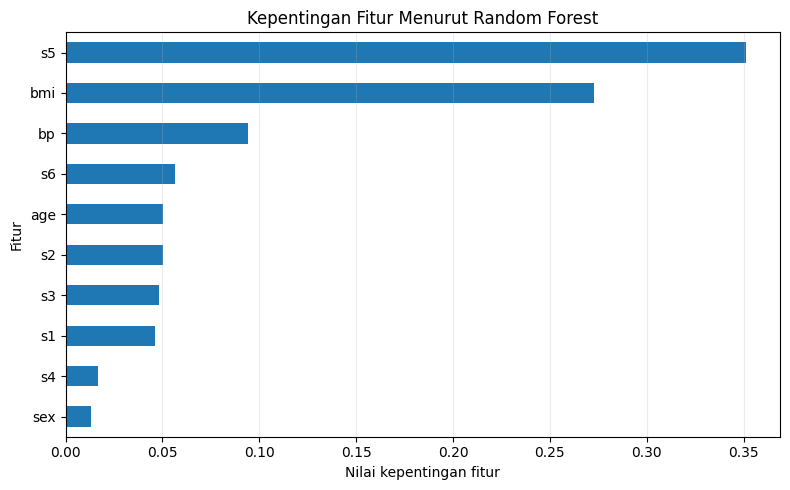

,Kepentingan
s5,0.3513
bmi,0.2726
bp,0.0941
s6,0.0565
age,0.0506
s2,0.0505
s3,0.0481
s1,0.0460
s4,0.0170
sex,0.0133


In [12]:
kepentingan = pd.Series(
    hutan.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(8, 5))
kepentingan.plot(kind="barh")
plt.xlabel("Nilai kepentingan fitur")
plt.ylabel("Fitur")
plt.title("Kepentingan Fitur Menurut Random Forest")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(kepentingan.sort_values(ascending=False).to_frame("Kepentingan").round(4))

## 13. Memeriksa prediksi terhadap nilai sebenarnya

Grafik ini membandingkan nilai prediksi dengan nilai target sebenarnya. Jika prediksi tepat, titik akan berada dekat garis diagonal.

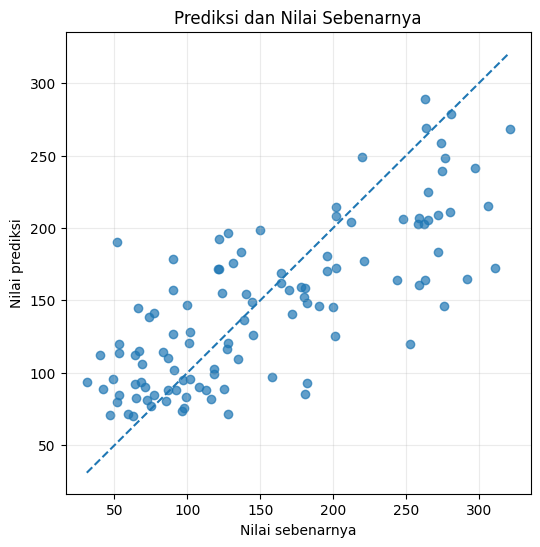

MAE: 41.12
RMSE: 52.22
R²: 0.569


In [13]:
model_terpilih = hutan
prediksi_akhir = model_terpilih.predict(X_test)

batas_min = min(y_test.min(), prediksi_akhir.min())
batas_maks = max(y_test.max(), prediksi_akhir.max())

plt.figure(figsize=(6, 6))
plt.scatter(y_test, prediksi_akhir, alpha=0.7)
plt.plot([batas_min, batas_maks], [batas_min, batas_maks], linestyle="--")
plt.xlabel("Nilai sebenarnya")
plt.ylabel("Nilai prediksi")
plt.title("Prediksi dan Nilai Sebenarnya")
plt.grid(alpha=0.25)
plt.show()

print("MAE:", round(mean_absolute_error(y_test, prediksi_akhir), 2))
print("RMSE:", round(mean_squared_error(y_test, prediksi_akhir) ** 0.5, 2))
print("R²:", round(r2_score(y_test, prediksi_akhir), 3))

## 14. Kesimpulan dan latihan mandiri

### Kesimpulan

- Pembelajaran mesin dapat digunakan untuk memperkirakan nilai numerik berdasarkan pola dalam data.
- KNN memakai kedekatan antar sampel, sehingga skala fitur perlu diperhatikan.
- Pohon Keputusan membangun aturan yang mudah dilihat, tetapi pohon yang terlalu rumit berisiko terlalu menyesuaikan data latihan.
- Random Forest menggabungkan banyak pohon untuk memperoleh prediksi yang lebih stabil.
- Gradient Boosting membangun model secara bertahap untuk memperbaiki kesalahan.
- Validasi silang membantu membandingkan model dengan lebih andal daripada hanya mengandalkan satu pembagian data.
- Pilihan model sebaiknya mempertimbangkan ukuran kesalahan, kestabilan, dan kebutuhan penjelasan hasil.

### Pertanyaan latihan

1. Model mana yang memperoleh RMSE terkecil pada data pengujian?
2. Apa perbedaan cara kerja Random Forest dan Gradient Boosting?
3. Mengapa validasi silang dapat memberikan gambaran kinerja yang lebih stabil?
4. Apa risiko jika kedalaman pohon dibuat terlalu besar?
5. Mengapa kepentingan fitur tidak sama dengan bukti hubungan sebab-akibat?

**Catatan:** angka hasil dapat berubah jika nilai acak, parameter, atau versi pustaka berubah. Dataset ini digunakan untuk latihan analisis, bukan untuk penilaian atau diagnosis kesehatan.